# Assignment 3

In [176]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy as sp

## Question 1

## Question 2
### Part a)
The method my RNG uses is as follows:
- generate a random number $x_i$ uniformly between 0 and 1 
- map $x_i$ to the inverse of the CDF of the Cauchy distribution at $x_i$

This is possible because the Cauchy distribution can be integrated analytically. First normalize this by integrating from $-\infty$ to $\infty$.
$$\int_{-\infty}^\infty  dy \left[\frac{1}{1+(\frac{y-a}{b})^2}\right] = \left[b\tan^{-1}\left(\frac{y-a}{b}\right)\right]_{y=-\infty}^{y=\infty} = b \pi$$

Then the CDF of the Cauchy distribution $F(x)$ is given by 
$$F(x) = \frac{1}{b\pi} \int_{-\infty}^x  dy \left[\frac{1}{1+(\frac{y-a}{b})^2}\right] = \frac{1}{b\pi}\left[b\tan^{-1}\left(\frac{y-a}{b}\right)\right]_{y=-\infty}^{y=x} = \frac{1}{\pi}\tan^{-1}\left(\frac{x-a}{b}\right) + \frac{1}{2}$$

This means that the inverse of this is 
$$F^{-1}(x) = b\tan \left(\pi\left(x - \frac{1}{2} \right)\right) + a $$

In [70]:
def cauchy_pdf(x,a,b):
    '''
    Cauchy distribution with parameters a and b.
    '''
    return 1/((1+((x-a)/b)**2)*b*np.pi)

In [75]:
def cauchy_cdf_inverse(x,a,b):
    '''
    Inverse of the CDF of the Cauchy distribution.
    '''
    return b*np.tan(np.pi*(x -1/2))+a

In [87]:
def draw_cauchy_vals(N,a,b):
    '''
    Draw N random numbers from a Cauchy distribution with parameters a and b. Returns a length N numpy array.
    '''
    uni_rand = np.random.uniform(0,1,N)
    return cauchy_cdf_inverse(uni_rand,a,b)

In [316]:
def fwhm_basic(bin_vals,bins):
    '''
    Finds the FWHM in a very clunky way using the bins and not interpolating. 
    '''
    bin_centres = bins[:-1]+np.diff(bins)[0]
    # intrp_bins = sp.interpolate.interp1d(bin_vals, bin_centres)
    max_ind = np.argmax(bin_vals)
    half_val = bin_vals[max_ind]/2
    
    min_hm = np.argmin(np.abs(bin_vals[:max_ind]-half_val))
    max_hm = np.argmin(np.abs(bin_vals[max_ind:]-half_val)) + max_ind

    # print(intrp_bins(half_val))

    return bins[max_hm] - bins[min_hm]

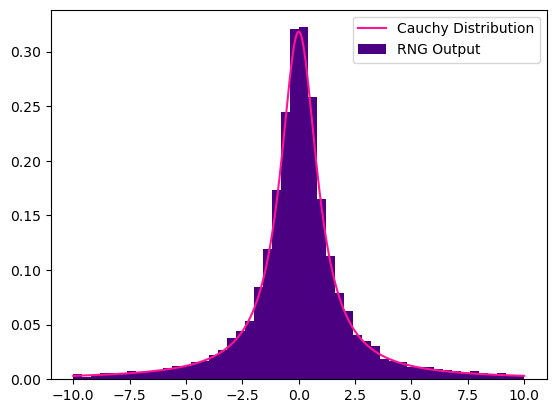

In [218]:
# plot the output with a Cauchy distribution curve superimposed 
cauchy_plt = np.linspace(-10,10,500)

fig,ax = plt.subplots(1,1)
ax.plot(cauchy_plt,cauchy_pdf(cauchy_plt,0,1),label='Cauchy Distribution',color='deeppink')

ax.hist(draw_cauchy_vals(10000,0,1),bins=50,range=(-10,10),density=True,label='RNG Output',color='indigo')

ax.legend()

### Part b)

2.333333333333334
The full width half max of this peak is 6.12. The variance is 711796.51.


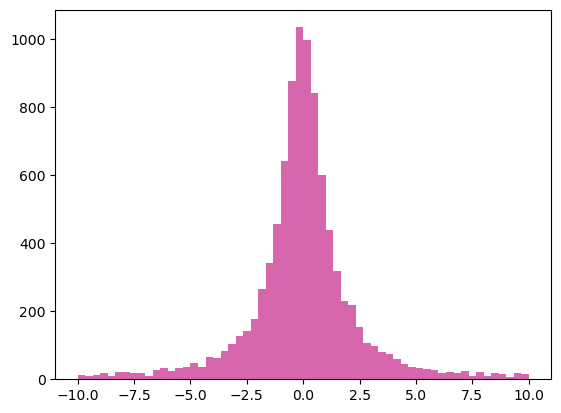

In [379]:
cauchy_vals = draw_cauchy_vals((10000,25),0,1)  # draw 25 numbers 10000 times
mean_vals = np.mean(cauchy_vals,axis=1)         # calculate their mean
var = np.var(mean_vals)   # calculate the variance of the peak

fig,ax = plt.subplots(1,1)
mean_vals_hist = ax.hist(mean_vals,bins=60,range=(-10,10),color='xkcd:pale magenta')

fwhm = sp.signal.peak_widths(mean_vals_hist[0],np.argmax(mean_vals_hist[0]).reshape((1)))[0]   # calculate the fwhm of the peak
print(fwhm_basic(mean_vals_hist[0],mean_vals_hist[1]))

print(f'The full width half max of this peak is {fwhm[0]:.2f}. The variance is {var:.2f}.')

### Part c)

2.333333333333334
The full width half max of this peak is 6.19. The variance is 2379999.74.


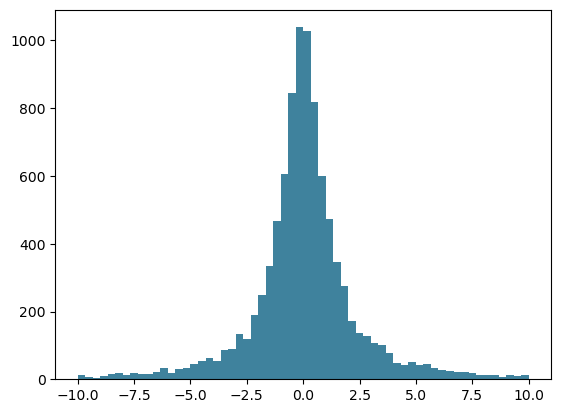

In [378]:
cauchy_vals = draw_cauchy_vals((10000,100),0,1)  # draw 100 numbers 10000 times
mean_vals = np.mean(cauchy_vals,axis=1)         # calculate their mean
var = np.var(mean_vals)   # calculate the variance of the peak

fig,ax = plt.subplots(1,1)
mean_vals_hist = ax.hist(mean_vals,bins=60,range=(-10,10),color='xkcd:dirty blue')

fwhm = sp.signal.peak_widths(mean_vals_hist[0],np.argmax(mean_vals_hist[0]).reshape((1)))[0]   # calculate the fwhm of the peak
print(fwhm_basic(mean_vals_hist[0],mean_vals_hist[1]))

print(f'The full width half max of this peak is {fwhm[0]:.2f}. The variance is {var:.2f}.')

The width of the distribution does not change significantly when going from $x_{25}$ to $x_{100}$.

### Part d)

0.4166666666666665
The full width half max of this peak is 4.46. The variance is 0.03.


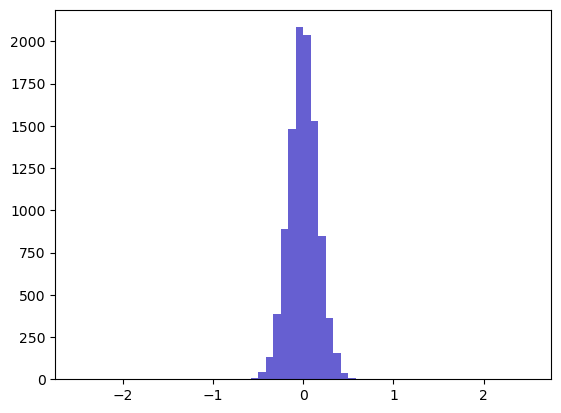

In [322]:
cauchy_vals = draw_cauchy_vals((10000,100),0,1)  # draw 100 numbers 10000 times
med_vals = np.median(cauchy_vals,axis=1)         # calculate their mean
fwhm = sp.signal.peak_widths(med_vals,np.argmax(med_vals).reshape((1)))[0]   # calculate the fwhm of the peak
var = np.var(med_vals)   # calculate the variance of the peak

fig,ax = plt.subplots(1,1)
med_vals_hist = ax.hist(med_vals,bins=60,range=(-2.5,2.5),color='xkcd:dark periwinkle')

fwhm = sp.signal.peak_widths(med_vals_hist[0],np.argmax(med_vals_hist[0]).reshape((1)))[0]   # calculate the fwhm of the peak
print(fwhm_basic(med_vals_hist[0],med_vals_hist[1]))

print(f'The full width half max of this peak is {fwhm[0]:.2f}. The variance is {var:.2f}.')

The method of this estimator is to take the median rather than the mean in the method above. 

This estimator has a MUCH smaller variance than the previous method and a smaller width peak.

This estimator is unbaised (its distribution is centered at 0, the actual value of $a$). It is also consistent as we can see below with the plots as the number of data points is increased.

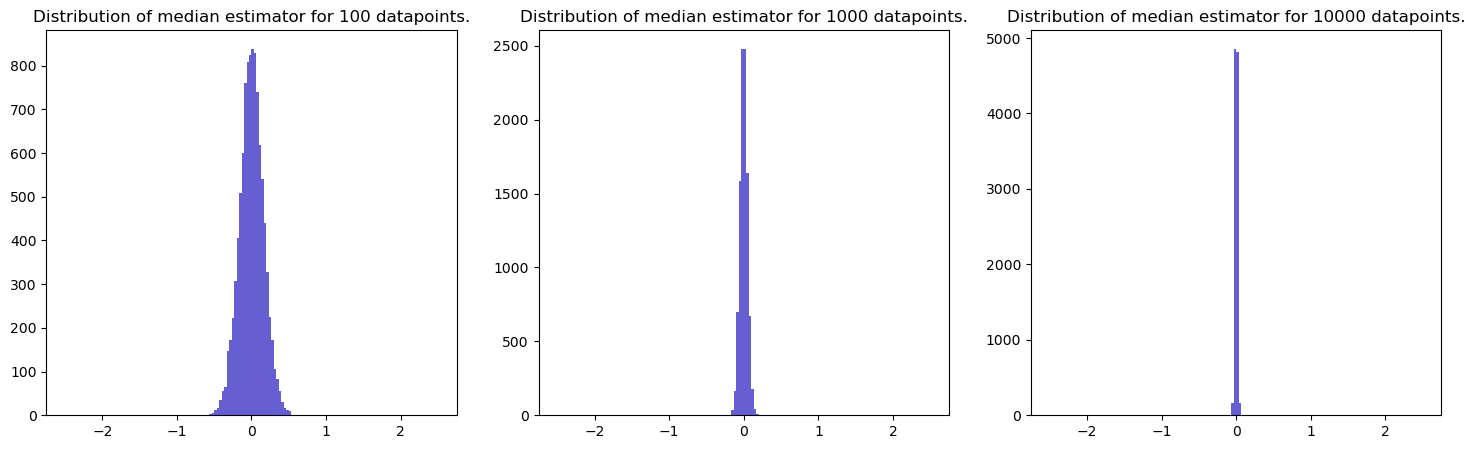

In [295]:
N_vals = (100,1000,10000)

fig,axs = plt.subplots(1,3,figsize=(18,5))

for n in range(3):

    cauchy_vals = draw_cauchy_vals((10000,N_vals[n]),0,1)  # draw N_vals numbers 10000 times
    med_vals = np.median(cauchy_vals,axis=1)         # calculate their mean
    med_vals_hist = axs[n].hist(med_vals,bins=150,range=(-2.5,2.5),color='xkcd:dark periwinkle')

    axs[n].set_title(f'Distribution of median estimator for {N_vals[n]} datapoints.')


### Part e)
An estimator for $b$ could be half of the the FWHM of the peak. Using the same method as above, simulating 100 data points and finding the FWHM each time.

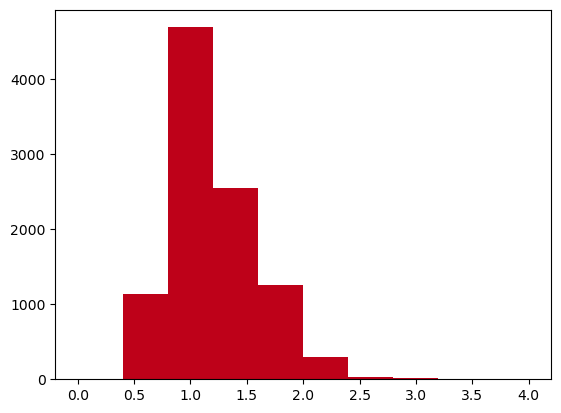

In [368]:
cauchy_vals = draw_cauchy_vals((10000,100),0,1)  # draw 100 numbers 10000 times

mini = -10
maxi = 10
nbins = 30
hists = np.apply_along_axis(lambda x: np.histogram(x,bins=nbins,range=(mini,maxi))[0],axis=1,arr=cauchy_vals) # histogram the drawn numbers over axis 1 

fwhms = []
bin_edges = np.linspace(mini,maxi,nbins+1)
for arr in hists:
    fwhms.append(fwhm_basic(arr,bin_edges)/2)

fwhms = np.array(fwhms)

fig,ax = plt.subplots(1,1)
mean_vals_hist = ax.hist(fwhms,bins=10,range=(0,4),color='xkcd:scarlet')

This appears to be unbiased since it peaks at 1 (the actual value of $b$). It should be noted that this isn't a symmetric distribution so its mean is higher than $b$. Based on the below plots, this estimator is also consistent. 

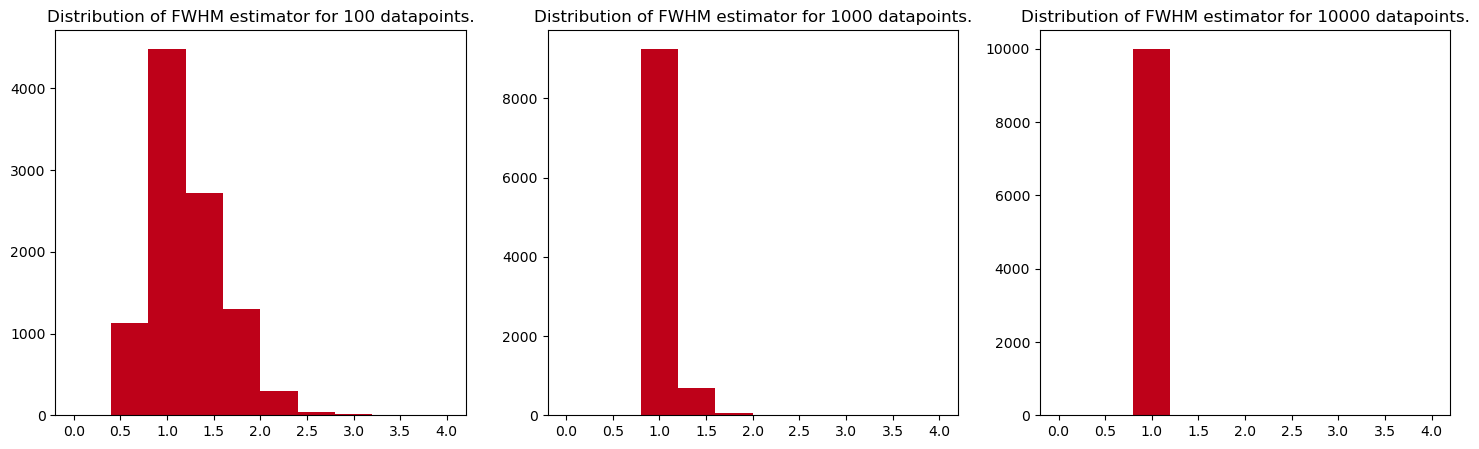

In [369]:
N_vals = (100,1000,10000)

fig,axs = plt.subplots(1,3,figsize=(18,5))

for n in range(3):

    cauchy_vals = draw_cauchy_vals((10000,N_vals[n]),0,1)  # draw N_vals numbers 10000 times

    mini = -10
    maxi = 10
    nbins = 30
    hists = np.apply_along_axis(lambda x: np.histogram(x,bins=nbins,range=(mini,maxi))[0],axis=1,arr=cauchy_vals) # histogram the drawn numbers over axis 1 

    fwhms = []
    bin_edges = np.linspace(mini,maxi,nbins+1)
    for arr in hists:
        fwhms.append(fwhm_basic(arr,bin_edges)/2)

    fwhms = np.array(fwhms)

    mean_vals_hist = axs[n].hist(fwhms,bins=10,range=(0,4),color='xkcd:scarlet')

    axs[n].set_title(f'Distribution of FWHM estimator for {N_vals[n]} datapoints.')

## Question 3
### Part a)

In [370]:
filename = 'hw3_planet_data.txt'
rad_vel_data = np.loadtxt(filename,dtype=float,skiprows=3).T

The number of data point is 1001.


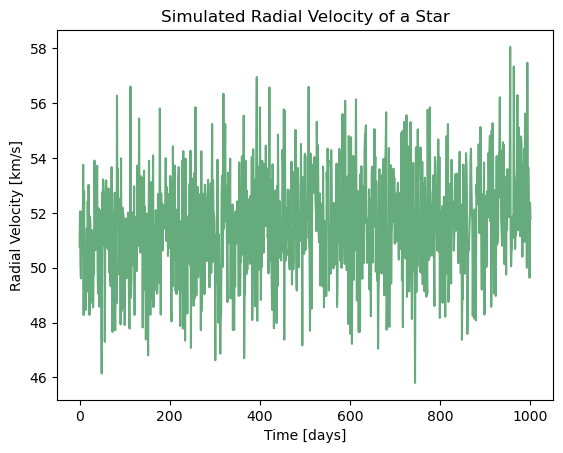

In [382]:
fig,ax = plt.subplots(1,1)
ax.plot(rad_vel_data[0],rad_vel_data[1],color='xkcd:tea')
ax.set_xlabel('Time [days]')
ax.set_ylabel('Radial Velocity [km/s]')
ax.set_title('Simulated Radial Velocity of a Star')

print(f'The number of data point is {len(rad_vel_data[0])}.')

### Part b)
Here we are told that the noise is Gaussian therefore we can use the $\chi^2$ distribution. There are 1001 data point and 2 or 3 free parameters for the first and second model respectively so these two models are $\chi^2$ distributions with 99 and 98 degrees of freedom respectively.

In [380]:
def model0(t,a0,b0):
    '''
    '''
    return a0 + b0*t

In [381]:
def model1(t,a1,b1,c1,T=50):
    '''
    '''
    return a1 + b1*t + c1*np.sin(2*np.pi*t/T)

In [477]:
def chi2_val(t,y,model,sigma,*args):
    '''
    '''
    unsummed = []
    for n in range(len(t)):
        unsummed.append([((y[n]-model(t[n],*args))/sigma)**2])

    summed = np.sum(np.concatenate(unsummed).T,axis=-1)
    return summed

    

In [646]:
# for many values of a,b,c, find chi squared

a = np.linspace(50.3,51.5,100)
b = np.linspace(0.0006,0.002,100)

aplt,bplt = np.meshgrid(a,b)

# get chi squared value for each a,b

mod0 = chi2_val(rad_vel_data[0],rad_vel_data[1],model0,2,aplt,bplt) # what is the 2 units per point

# find value of chi squared pmf at that point 
chi2_dist = sp.stats.chi2.pdf(mod0,99)


maxval = np.argmax(chi2_dist)
print('The max values are:',aplt.flatten()[maxval],bplt.flatten()[maxval])

The max values are: 50.94242424242424 0.0012787878787878788


''

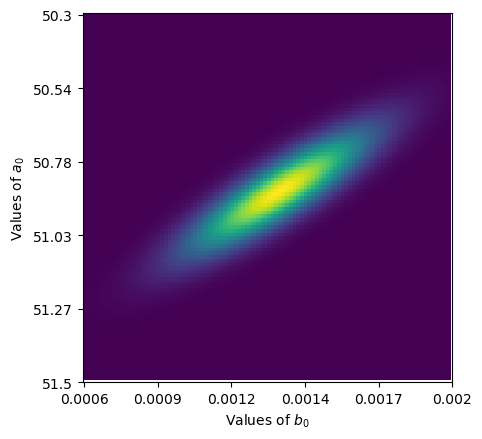

In [648]:
fig,ax = plt.subplots(1,1)
ax.imshow(chi2_dist)
ax.set_yticks(np.linspace(0,100,6), labels=list(a[::20].round(2)) + [np.max(a)])
ax.set_xticks(np.linspace(0,100,6), labels=list(b[::20].round(4)) + [np.max(b)])
ax.set_xlabel('Values of $b_0$')
ax.set_ylabel('Values of $a_0$')

''

In [632]:
# for many values of a,b,c, find chi squared

a = np.linspace(50,52,50)
b = np.linspace(0.0004,0.003,50)
c = np.linspace(1,3,50)

aplt,bplt,cplt = np.meshgrid(a,b,c)

# get chi squared value for each a,b

mod1 = chi2_val(rad_vel_data[0],rad_vel_data[1],model1,2,aplt,bplt,cplt) # what is the 2 units per point

# find value of chi squared pmf at that point 
chi2_dist = sp.stats.chi2.pdf(mod1,99)

In [633]:
maxval = np.argmax(chi2_dist)
print(aplt.flatten()[maxval],bplt.flatten()[maxval],cplt.flatten()[maxval])

50.857142857142854 0.0004 1.7755102040816326


### Part c)

In [637]:
p0 = sp.integrate.dblquad(lambda y,x: chi2_val(rad_vel_data[0],rad_vel_data[1],model0,2,x,y),
                     48,
                     54,
                     0,
                     0.005)[0]

In [638]:
p1 = sp.integrate.tplquad(lambda z,y,x: chi2_val(rad_vel_data[0],rad_vel_data[1],model1,2,x,y,z),
                     48,
                     54,
                     0,
                     0.005,
                     0,
                     4)[0]

In [645]:
bayes_fact = p1/p0

print(f'The Bayes factor given that each model is equally likely is {bayes_fact:.2f}. \nSince this is greater than 1, this can be interpreted as the data more strongly supporting hypothesis 1 over hypothesis 0. \nHowever, with it being so small, this isn\'t strong evidence.')

The Bayes factor given that each model is equally likely is 5.42. 
Since this is greater than 1, this can be interpreted as the data more strongly supporting hypothesis 1 over hypothesis 0. 
However, with it being so small, this isn't strong evidence.


## Question 4